<a href="https://colab.research.google.com/github/gabrielaramoz/tarea2/blob/main/Tarea_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Análisis bivariado y estudio de variables independientes**

## Importación de librerías

In [ ]:
from google.colab import files # Para subir y descargar archivos en Colab
import pandas as pd # Para manipulación y análisis de datos
import io # Para lectura y escritura de archivos en memoria
import matplotlib.pyplot as plot # Para crear gráficos estáticos básicos
import seaborn as sns # Para visualizaciones estadísticas avanzadas
import numpy as np # Para cálculos numéricos y operaciones con matrices
from scipy.stats import norm # Para trabajar con la distribución normal
from scipy.stats import shapiro # Para realizar la prueba de normalidad (Shapiro-Wilk)
import plotly.express as px # Para crear gráficos interactivos
from scipy.stats import skew, kurtosis # Para calcular asimetría y curtosis
from sklearn.linear_model import LinearRegression # Para realizar regresión lineal
from scipy.stats import pearsonr, spearmanr, kendalltau # Para calcular correlaciones

## Subida datos y lectura del archivo CSV

In [ ]:
uploaded = files.upload()  # Sube el archivo SCV

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


In [ ]:
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
# Se carga el archivo como CSV cargado con la función upload()

tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1')
# (1) Se usa read de Pandas para trabajar con el archiivo CSV
# (2) Se usa el separador «,» para leer los datos
# (3) Se usa codificación «latin-1» para que lea los caracteres latinos

tabla.head(4) # Se muestran las cuatro primeras filas de la tabla

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1
50,573,1,1,NaN,2,7,5,2024,5,1,...,1,NaN,1,2,2.0,27,3,7,1.0,1


## Creación de la subtabla

In [ ]:
df = tabla[["EDAD_PADRE", "N_EMB"]]
# Se extraen las variables variables en una tabla.
#   EDAD_PADRE: «Edad del padre en años cumplidos a la fecha del nacimiento de este hijo».
#   N_EMB: «Número de embarazos, incluido el presente».

df.head(3) # Se muestran las tres primeras filas de la tabla

,EDAD_PADRE,N_EMB
COD_DPTO,,
76,39,2
19,27,3
41,28,3


## Análisis de la variable EDAD_PADRE

### Histograma

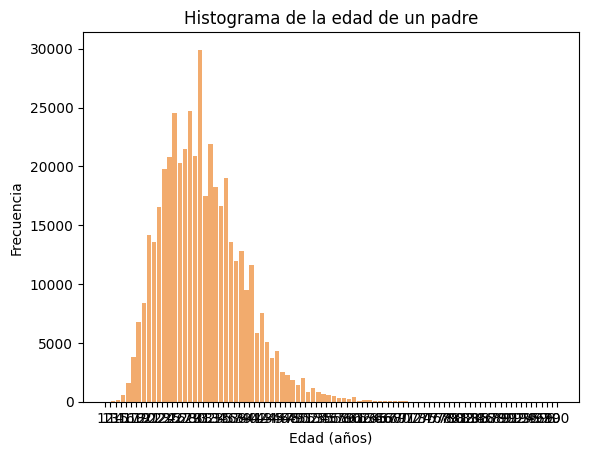

In [ ]:
intervalos = range(min(df.EDAD_PADRE), max(df.N_EMB) + 2)  # Calcula los extremos de los intervalos

plot.hist(x=df.EDAD_PADRE, bins=intervalos, color='#F2AB6D', rwidth=0.85) # Construye el histograma con la función «hist»
plot.title('Histograma de la edad de un padre')  # Agrega un título al histograma con «title»
plot.xlabel('Edad (años)') # Añadre un título para el eje x
plot.ylabel('Frecuencia') # Añadre un título para el eje y
plot.xticks(intervalos)
plot.show()  # dibujamos el histograma

No se observan muy bien los valores correspondientes a la variable de la edad del padre porque hay muchos valores, entre ellos algunos mayores a 100. Estos datos hay que depurarlos.

In [ ]:
# Filtra df: elimina edades de padre imposibles (> 100)
# y registros con N_EMB = 99 (código de dato faltante).
df1 = df[(df.EDAD_PADRE <= 100) & (df.N_EMB != 99)]

# Muestra las tres primeras filas de la tabla df1
df1.head(3)

,EDAD_PADRE,N_EMB
COD_DPTO,,
76,39,2
19,27,3
41,28,3


Se crea una nueva tabla con las variable, pero añadiendo una restricción de valores.

/tmp/ipykernel_3049/2846162805.py:21: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plot.plot(x, p, 'k', linewidth=2, label='Distribución Normal', color='darkblue')


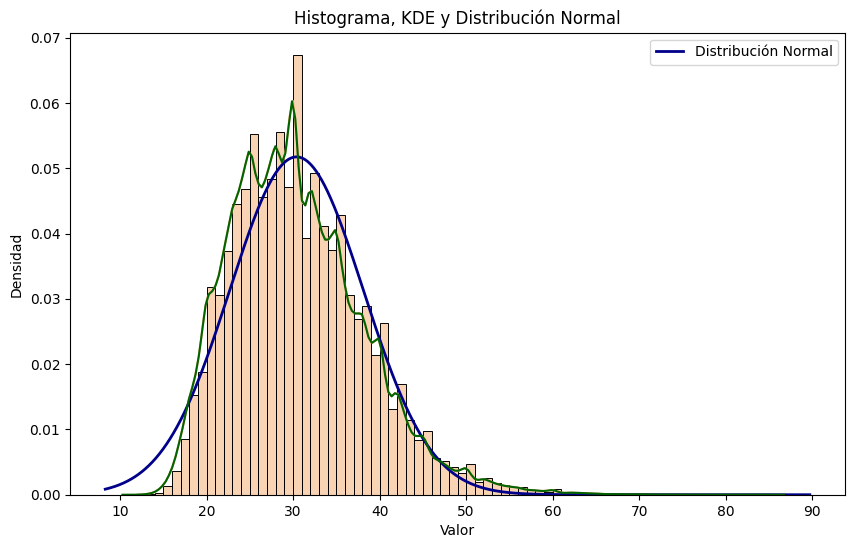

In [ ]:
# Crea los bordes de los intervalos
intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) + 2)

# Abre una figura vacía de 10 x 6 pulgadas para dibujar el gráfico.
plot.figure(figsize=(10, 6))

# Dibuja el histograma de edades con intervalos de amplitud 1, normalizado a área 1 (densidad),
# barras azul claro con borde negro, e incluye un KDE superpuesto.
sns.histplot(x=df1.EDAD_PADRE, bins=intervalos1, kde=True, stat='density', color='#F2AB6D', edgecolor='black')

# Recupera los límites del eje x que dejó el histograma, para dibujar las curvas en ese mismo rango.
xmin, xmax = plot.xlim()

# Genera 1000 puntos equiespaciados entre xmin y xmax sobre los cuales se evaluará la curva normal.
x = np.linspace(xmin, xmax, 1000)

# Calcula la densidad normal en esos 1000 puntos, usando la media y la desviación estándar muestrales de las edades.
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

# Traza la curva normal en azul oscuro con grosor 2 y la etiqueta 'Distribución Normal' para la leyenda.
plot.plot(x, p, 'k', linewidth=2, label='Distribución Normal', color='darkblue')

# Superpone un segundo KDE de las edades en verde oscuro.
sns.kdeplot(x=df1.EDAD_PADRE, color='darkgreen')

# Asigna el título del gráfico.
plot.title('Histograma, KDE y Distribución Normal')

# Nombra el eje x.
plot.xlabel('Valor')

# Nombra el eje y (densidad, no frecuencia).
plot.ylabel('Densidad')

# Muestra el recuadro de leyenda con la etiqueta definida en plot.plot().
plot.legend()

# Renderiza y muestra la figura terminada.
plot.show()

Sea $X$ la edad del padre de un recién nacido en Colombia. Descriptivamente, la función de densidad de probabilidad estimada mediante un método Kernel (línea verde oscuro) no coincide con la función de densidad de probabilidad bajo el supuesto de normalidad (línea azul). Por tanto, no resulta adecuado modelar la variable mediante una distribución normal $X \sim \text{Normal}(\bar{x}, s_x^2)$.

### Prueba de normalidad

In [ ]:
# Aplica la prueba de Shapiro-Wilk sobre TODOS los valores de la columna EDAD_PADRE
shapiro(df1.EDAD_PADRE)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443777.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9677117198585043), pvalue=np.float64(7.6156069148173195e-109))

Bajo un nivel de significación de α = 0,05, la regla de decisión establece que se rechaza la hipótesis nula cuando el valor p es inferior a 0,05. Por el
contrario, si el valor p es mayor o igual que 0,05, no existen evidencias suficientes para rechazarla.

Dado que en la prueba realizada se obtuvo un valor p ≈ 0,0 (< 0,05), se rechaza la hipótesis nula de normalidad. Por consiguiente, se concluye que la
variable aleatoria «edad del padre de un recién nacido en Colombia» no se ajusta a una distribución normal.

In [ ]:
# Cuenta cuántos valores NO NULOS contiene la columna EDAD_PADRE del df filtrado.
df1.EDAD_PADRE.count()

np.int64(443777)

Aunque la prueba de normalidad lleva al rechazo de la hipótesis nula, este resultado puede estar influenciado por el gran tamaño de la muestra, como se observa al calcular el número de registros mediante la función count(). Cuando se dispone de una gran cantidad de datos, incluso pequeñas desviaciones respecto a la normalidad pueden resultar estadísticamente significativas.

Por esta razón, se adopta un enfoque de aprendizaje automático, evitando basar el análisis exclusivamente en intervalos de confianza y pruebas de hipótesis.

In [ ]:
# Genera 100 enteros aleatorios con reemplazo en el rango [0, len(df1))
idx = np.random.randint(len(df1.EDAD_PADRE), size=100)

# Aplica Shapiro-Wilk sobre los ÍNDICES del dataframe
shapiro(df1.EDAD_PADRE.index[idx])

ShapiroResult(statistic=np.float64(0.830917345820736), pvalue=np.float64(2.4862693298619085e-09))

Como el valor p (igual a $1.000675320383948 \times 10^{-9}$) es menor que 0,05, se rechaza la hipótesis nula de normalidad. En consecuencia, los datos sugieren que la edad de los padres de los recién nacidos en Colombia no se ajusta a una distribución

### Diagrama de cajas y bigotes

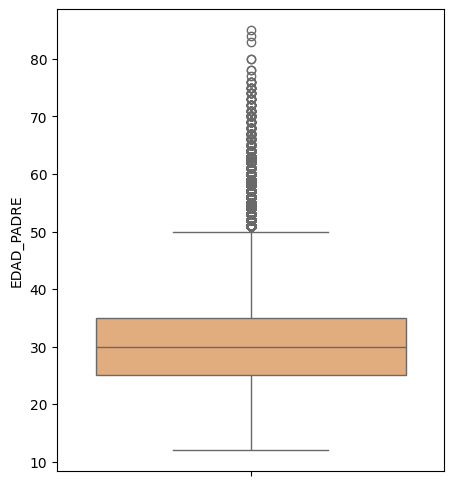

In [ ]:
# Crea un lienzo (figura) de 5 pulgadas de ancho por 6 de alto.
plot.figure(figsize=(5, 6))

# Dibuja un diagrama de caja (boxplot) horizontal para la distribución de las edades del padre.
sns.boxplot(df1.EDAD_PADRE, color='#F2AB6D', saturation=0.75)

# Renderiza y muestra el gráfico final en pantalla.
plot.show()


Se considera que la edad de un padre de un recién nacido en Colombia es un valor atípico cuando supera los 50 años. Del diagrama de caja se observa que el primer cuartil es aproximadamente 25 años, la media aritmética es cercana a 29 años y
el tercer cuartil es aproximadamente 35 años.

El rango intercuartílico se calcula como la diferencia entre el tercer y el primer cuartil:

$\text{Rango intercuartílico} = Q_3 - Q_1 = 35 - 25 = 10 \text{ años}$

Por tanto, el 50 % central de las edades de los padres se encuentra aproximadamente entre los 25 y los 35 años.

### Diagrama de puntos

In [ ]:
plot.figure(figsize=(5, 5))

fig = px.strip(df1.EDAD_PADRE, orientation='h')

fig.show()


<Figure size 500x500 with 0 Axes>

De acuerdo con el diagrama de puntos se observa una alta variabilidad de la edad de un padre de un recién Nacido en Colombia

### Medidas descriptivas

In [ ]:
def calcular_estadisticas(datos):
    media = np.mean(datos)
    varianza = np.var(datos)
    asimetria = skew(datos)
    curtosis = kurtosis(datos)
    return media, varianza, asimetria, curtosis

media, varianza, asimetria, curtosis = calcular_estadisticas(df1.EDAD_PADRE)

print(f"Media: {media}")
print(f"Varianza: {varianza} y la variación estándar {np.std(df1.EDAD_PADRE)}")
print(f"Asimetría: {asimetria}")
print(f"Curtosis: {curtosis}")

Media: 30.399666949841926
Varianza: 59.42512313787833 y la variación estándar 7.708769236258037
Asimetría: 0.7422600985923384
Curtosis: 0.8607555699997431


* La edad promedio de los padres de los recién nacidos en Colombia es aproximadamente 29,7 años.

* La desviación estándar es aproximadamente 7,62 años, lo que indica que las edades de los padres suelen diferir de la media en cerca de 7,62 años.

* La distribución de la edad de los padres presenta asimetría positiva; es decir, existen algunos valores altos que desplazan la distribución hacia la derecha.

* La distribución es platicúrtica, lo que indica una menor concentración de los datos alrededor de la media y colas menos pronunciadas en comparación con una distribución normal.

## Análisis de la variable N_EMB

Sea $Y$ el número de embarazos de la madre, contando el actual. Es discreta; 99 = sin información.

### Histograma

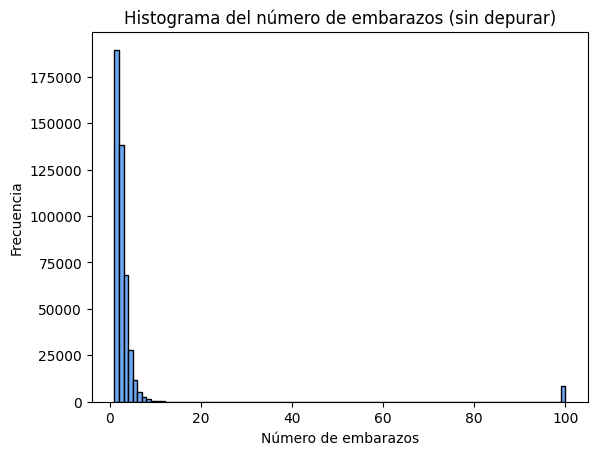

In [ ]:
intervalos = range(min(df.N_EMB), max(df.N_EMB) + 2)  # Intervalos de 1 en 1

plot.hist(x=df.N_EMB, bins=intervalos, color='#6DA9F2', edgecolor='black')  # Histograma sin depurar
plot.title('Histograma del número de embarazos (sin depurar)')  # Título
plot.xlabel('Número de embarazos')  # Eje x
plot.ylabel('Frecuencia')  # Eje y
plot.show()  # Muestra el gráfico

La barra en 99 es "sin información"; `df1` la excluye.

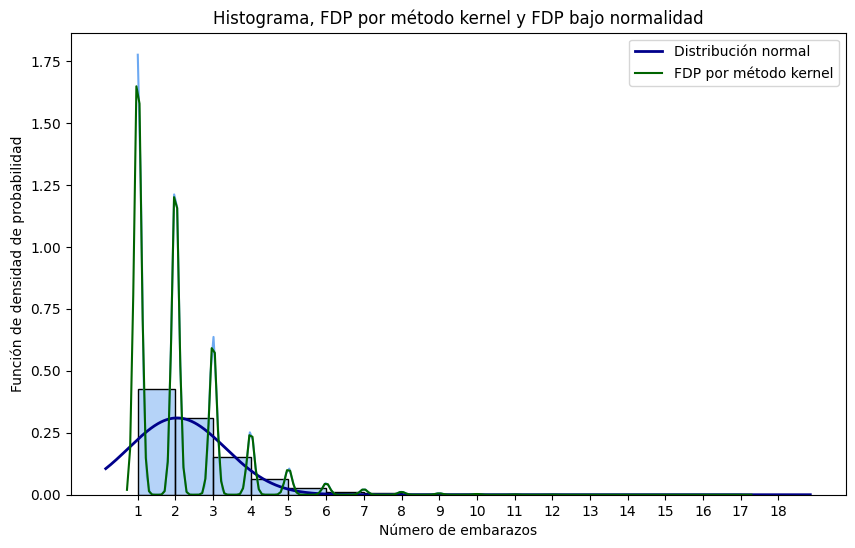

In [ ]:
intervalos1 = range(min(df1.N_EMB), max(df1.N_EMB) + 2)  # Intervalos de 1 en 1

plot.figure(figsize=(10, 6))  # Tamaño de la figura
sns.histplot(x=df1.N_EMB, bins=intervalos1, kde=True, stat='density', color='#6DA9F2', edgecolor='black')  # Histograma + curva kernel

xmin, xmax = plot.xlim()  # Límites del eje x
x = np.linspace(xmin, xmax, 1000)  # Puntos de la curva normal
p = norm.pdf(x, np.mean(df1.N_EMB), np.std(df1.N_EMB))  # Normal con la media y desviación de N_EMB
plot.plot(x, p, linewidth=2, label='Distribución normal', color='darkblue')  # Curva normal

sns.kdeplot(x=df1.N_EMB, color='darkgreen', label='FDP por método kernel')  # Curva kernel en verde

plot.title('Histograma, FDP por método kernel y FDP bajo normalidad')  # Título
plot.xlabel('Número de embarazos')  # Eje x
plot.ylabel('Función de densidad de probabilidad')  # Eje y
plot.xticks(intervalos1)  # Marcas en cada intervalo
plot.legend()  # Leyenda
plot.show()  # Muestra el gráfico

### Prueba de normalidad

$H_0$: $Y$ es normal. Se rechaza si el valor p < 0,05.

In [ ]:
shapiro(df1.N_EMB)  # Shapiro-Wilk con todos los datos

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning:

scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443777.



ShapiroResult(statistic=np.float64(0.7612364942886237), pvalue=np.float64(1.61744115214665e-170))

In [ ]:
df1.N_EMB.count()  # Número de datos

np.int64(443777)

Valor p ≈ 0, pero con 443.777 datos la prueba casi siempre rechaza; se repite con 100 datos al azar.

In [ ]:
np.random.seed(2024)  # Fija la muestra: así el valor p no cambia cada vez que se corre
idx = np.random.randint(len(df1.N_EMB), size=100)  # 100 posiciones al azar
shapiro(df1.N_EMB.iloc[idx])  # Shapiro-Wilk con la muestra

ShapiroResult(statistic=np.float64(0.8250093044592585), pvalue=np.float64(1.5683542136657102e-09))

Valor p = $1,57 \times 10^{-9}$ < 0,05: se rechaza $H_0$. N_EMB no es normal, como sugería el histograma.

### Diagrama de cajas y bigotes

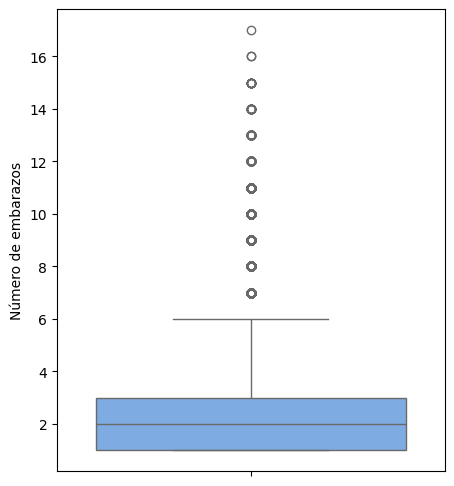

In [ ]:
plot.figure(figsize=(5, 6))  # Tamaño de la figura
sns.boxplot(df1.N_EMB, color='#6DA9F2', saturation=0.75)  # Diagrama de caja
plot.ylabel('Número de embarazos')  # Eje y
plot.show()  # Muestra el gráfico

$Q_1 = 1$, mediana $= 2$, $Q_3 = 3$; RIC $= 3 - 1 = 2$: la mitad central de las madres tiene entre 1 y 3 embarazos. Más de 6 es atípico (puntos hasta 17).

### Diagrama de puntos

In [ ]:
fig = px.strip(df1, x='N_EMB', orientation='h')  # Un punto por dato (tarda en cargar)
fig.show()  # Muestra el gráfico

Los puntos se amontonan entre 1 y 6; después quedan pocos, hasta 17.

### Medidas descriptivas

In [ ]:
media = np.mean(df1.N_EMB)  # Promedio
varianza = np.var(df1.N_EMB)  # Varianza
asimetria = skew(df1.N_EMB)  # Coeficiente de asimetría
curtosis = kurtosis(df1.N_EMB)  # Curtosis

print(f"Media: {media}")  # Muestra los resultados
print(f"Varianza: {varianza} y la desviación estándar {np.std(df1.N_EMB)}")
print(f"Asimetría: {asimetria}")
print(f"Curtosis: {curtosis}")

Media: 2.0416177494552445
Varianza: 1.657955148165853 y la desviación estándar 1.2876160717255174
Asimetría: 1.9966262790249505
Curtosis: 6.605849499993035


* Media (2,04): en promedio, la madre va en su segundo embarazo.
* Desviación estándar (1,29): los datos se alejan unos 1,3 embarazos de la media. La varianza (1,66) no se interpreta.
* Asimetría (2,00 > 0): positiva; pocas madres con muchos embarazos alargan la cola derecha.
* Curtosis (6,61 > 3): leptocúrtica; datos muy concentrados cerca de la media.

### Conclusión sobre N_EMB

La mayoría de los nacimientos de 2024 son del primer o segundo embarazo(mediana 2, media 2,04). N_EMB es asimétrica positiva, leptocúrtica y no es normal.

Moda y mediana: lo más común es que sea el primer embarazo de la madre (la moda es 1 y el 42,5 % de los nacimientos son así). La mediana es 2, y casi tres de cada cuatro nacimientos (73,6 %) son de madres en su primer o segundo embarazo.

Valores atípicos: como Q₁ = 1, Q₃ = 3 y el RIC es 2, se consideran atípicas las madres con más de 6 embarazos (3 + 1,5 · 2 = 6). Son 4876 casos, solo el 1,1 % del total, y el máximo llega a 17.

Media y mediana: la media (2,04) queda un poco por encima de la mediana (2). Esto coincide con la asimetría positiva: unas pocas madres con muchos embarazos jalan el promedio hacia arriba.

## Análisis bivariado y relación

En estadística, la dependencia y la correlación describen cómo se relacionan dos variables aleatorias, aunque no son sinónimos. La dependencia es un concepto general que indica si el valor de una variable aporta información sobre la otra; la correlación, en cambio, cuantifica el grado de asociación entre ambas mediante coeficientes como el de Pearson (relación lineal) o los de Spearman y Kendall (relación monotónica).

## Diagarma de dispersión

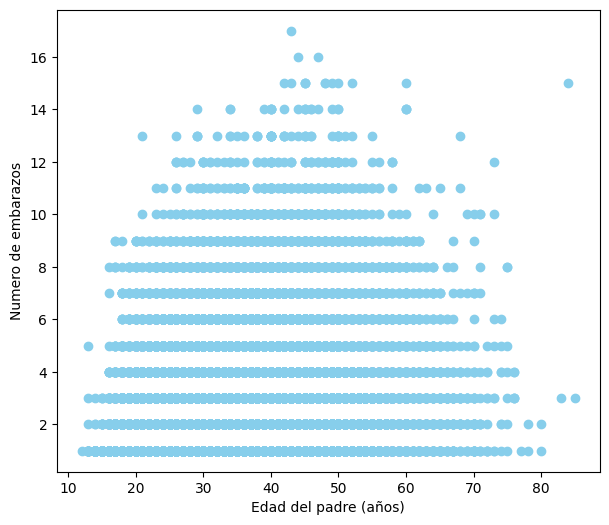

In [ ]:
plot.figure(figsize=(7, 6))
plot.scatter(df1["EDAD_PADRE"], df1["N_EMB"], color = "skyblue", marker = "o")
plot.xlabel('Edad del padre (años)')
plot.ylabel('Numero de embarazos')
plot.show()

El diagrama de dispersión muestra una nube de puntos sin un patrón definido, lo que indica ausencia de correlación lineal entre las variables. En el ejemplo, el número de embarazos de la mujer y la edad del padre en Colombia no evidencian una asociación lineal: no se observa que edades paternas menores se asocien con un mayor número de embarazos, ni que edades mayores se asocien con un menor número. Cabe precisar, desde una perspectiva sociológica, que el número de embarazos no equivale necesariamente al número de hijos, dado que puede haber gestaciones que no culminen en nacimiento.

## Recta de regresión

In [ ]:
modelo = LinearRegression()
modelo.fit(np.array(df1["EDAD_PADRE"]).reshape(-1, 1), np.array(df1["N_EMB"]).reshape(-1, 1))


predi_lineal = modelo.predict(np.array(df1["EDAD_PADRE"]).reshape(-1, 1))
predi_lineal

array([[2.53009455],
       [1.84852541],
       [1.90532284],
       ...,
       [1.96212027],
       [1.45094341],
       [2.07571512]])

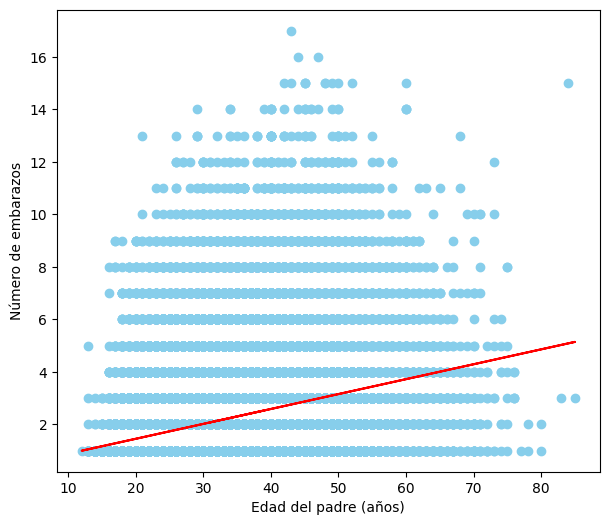

In [ ]:
plot.figure(figsize=(7, 6))
plot.scatter(df1["EDAD_PADRE"], df1["N_EMB"], color = "skyblue", marker = "o")

plot.plot(df1["EDAD_PADRE"], predi_lineal, linestyle='-', color = "red")
plot.xlabel('Edad del padre (años)')

plot.ylabel('Número de embarazos')
plot.show()

De acuerdo con la recta de regresión ajustada, cuya pendiente es positiva, se evidencia una correlación positiva entre las variables: a mayor edad del hombre en Colombia, mayor es, en promedio, el número de embarazos de su pareja.

## Coeficientes de relación

In [ ]:
coef_pearson = np.corrcoef(df1["EDAD_PADRE"], df1["N_EMB"])[0, 1]
coef_spearman, _ = spearmanr(df1["EDAD_PADRE"], df1["N_EMB"])
coef_kendall, _ = kendalltau(df1["EDAD_PADRE"], df1["N_EMB"])
print(f"Los coeficientes de correlación de Pearson, Spearman y Kendall son respectivamente {coef_pearson}, {coef_spearman} y {coef_kendall}.")

Los coeficientes de correlación de Pearson, Spearman y Kendall son respectivamente 0.3400379040191506, 0.3671706831050918 y 0.28723812222507816.


Los valores de los tres coeficientes de correlación —Pearson ($r≈0.340$), Spearman ($ρ≈0.367$) y Kendall ($τ≈0.287$)— son positivos y de magnitud entre baja y moderada, lo que indica que las variables aleatorias EDAD_PADRE y N_EMB están débilmente correlacionadas. Esto se traduce en que, en Colombia, la edad del padre y el número de embarazos de su pareja guardan una asociación positiva de baja intensidad: a mayor edad del hombre, tiende a observarse un mayor número de embarazos en la mujer con quien comparte el registro.